# 窒素：共通の0次元反応計算

`data/cases/nitrogen.json` の条件と、ZDPlasKin由来の21種・96反応を使います。
純N₂、1000 Td、300 K、101325 Pa、1 ns、初期電子・N₂⁺密度は各 **10¹⁴ m⁻³** です。
このケースは初期状態で求めた定常EEDFの係数を固定して密度を積分します。

他のガスも同じ `load_case → simulate → save_result` を使います。
反応機構・粒子種・断面積・第三体はケースが参照する入力で定義します。

In [11]:
from importlib import import_module
from pathlib import Path
import sys
import json

here = Path.cwd().resolve()
candidates = [here, *here.parents, here / "Py3ZDPlasChem-master"]
MODEL_DIR = next(
    path for path in candidates if (path / "plasglo").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
load_case = import_module("plasglo").load_case
simulate = import_module("plasglo").simulate
plot_result = import_module("plasglo").plot_result
save_result = import_module("plasglo").save_result
OUTPUTS_DIR = import_module("plasglo.paths").OUTPUTS_DIR


## 条件

標準条件はケースJSONで管理します。ここではBOLOS格子数を1600に指定します。
例：`case.with_updates(field={"td": 500}, solver={"end_ns": 0.5})`。
組成・圧力を変更するときは、明示した `initial_densities_m3` も整合させてください。
初期密度の値はすべてm⁻³で、cm⁻³からの換算は入力作成時に行います。

In [12]:
CASE_NAME = "nitrogen"  # bundled: nitrogen / argon / air; またはJSONのパス
case = load_case(CASE_NAME).with_updates(electrons={"cells": 1600})
OUTPUT_DIR = OUTPUTS_DIR / "notebooks" / case.source.stem
print(json.dumps(case.data, ensure_ascii=False, indent=2))


{
  "schema_version": 1,
  "name": "nitrogen",
  "mechanism": {
    "schema_version": 1,
    "species": [
      {
        "name": "E",
        "composition": {},
        "charge": -1,
        "electron": true
      },
      {
        "name": "N2",
        "composition": {
          "N": 2
        },
        "charge": 0,
        "excited": false
      },
      {
        "name": "N2^+",
        "composition": {
          "N": 2
        },
        "charge": 1,
        "excited": false
      },
      {
        "name": "N2(V1)",
        "composition": {
          "N": 2
        },
        "charge": 0,
        "excited": true
      },
      {
        "name": "N2(V2)",
        "composition": {
          "N": 2
        },
        "charge": 0,
        "excited": true
      },
      {
        "name": "N2(V3)",
        "composition": {
          "N": 2
        },
        "charge": 0,
        "excited": true
      },
      {
        "name": "N2(V4)",
        "composition": {
          "N": 2
     

## 計算

In [13]:
result = simulate(case)


C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\py3zdplaschem\solvers\simulation.py:550: UserWarning: Collision-data coverage or weak-ionization screen exceeded; review the case assumptions.
  warnings.warn(


## 保存則と計算条件の確認

In [14]:
print(json.dumps(result.diagnostics, ensure_ascii=False, indent=2))
assert result.diagnostics["max_atom_relative_error"] < 1e-8
assert result.diagnostics["max_charge_residual_over_initial_density"] < 1e-8


{
  "case_name": "nitrogen",
  "case_file": "C:\\Users\\daiko\\Documents\\Python_venvSystem\\3.14system\\Py3ZDPlasChem\\Py3ZDPlasChem-master\\data\\cases\\nitrogen.json",
  "python_executable": "c:\\Users\\daiko\\Documents\\Python_venvSystem\\3.14system\\Py3ZDPlasChem\\env_Py3ZDPlasChem\\Scripts\\python.exe",
  "field_td": 1000.0,
  "field_duration_ns": null,
  "final_field_td": 1000.0,
  "end_ns": 1.0,
  "gas_temperature_K": 300.0,
  "pressure_Pa": 101325.0,
  "initial_gas_density_m3": 2.446313291792483e+25,
  "initial_mole_fractions": {
    "N2": 1.0
  },
  "species_count": 21,
  "reaction_count": 96,
  "elements": [
    "N"
  ],
  "rtol": 1e-08,
  "atol_density_m3": 0.0001,
  "min_density_m3": 0.0,
  "max_atom_relative_error": 1.3322676295447421e-15,
  "max_net_charge_error_m3": 1692544402.0777607,
  "max_charge_residual_over_initial_density": 6.918755695586257e-17,
  "max_ion_fraction": 0.126350669828039,
  "max_ground_gas_relative_change": 0.9975312831519756,
  "max_electron_densi

## 密度履歴

元素組成・電荷のメタデータに基づいて描画します。

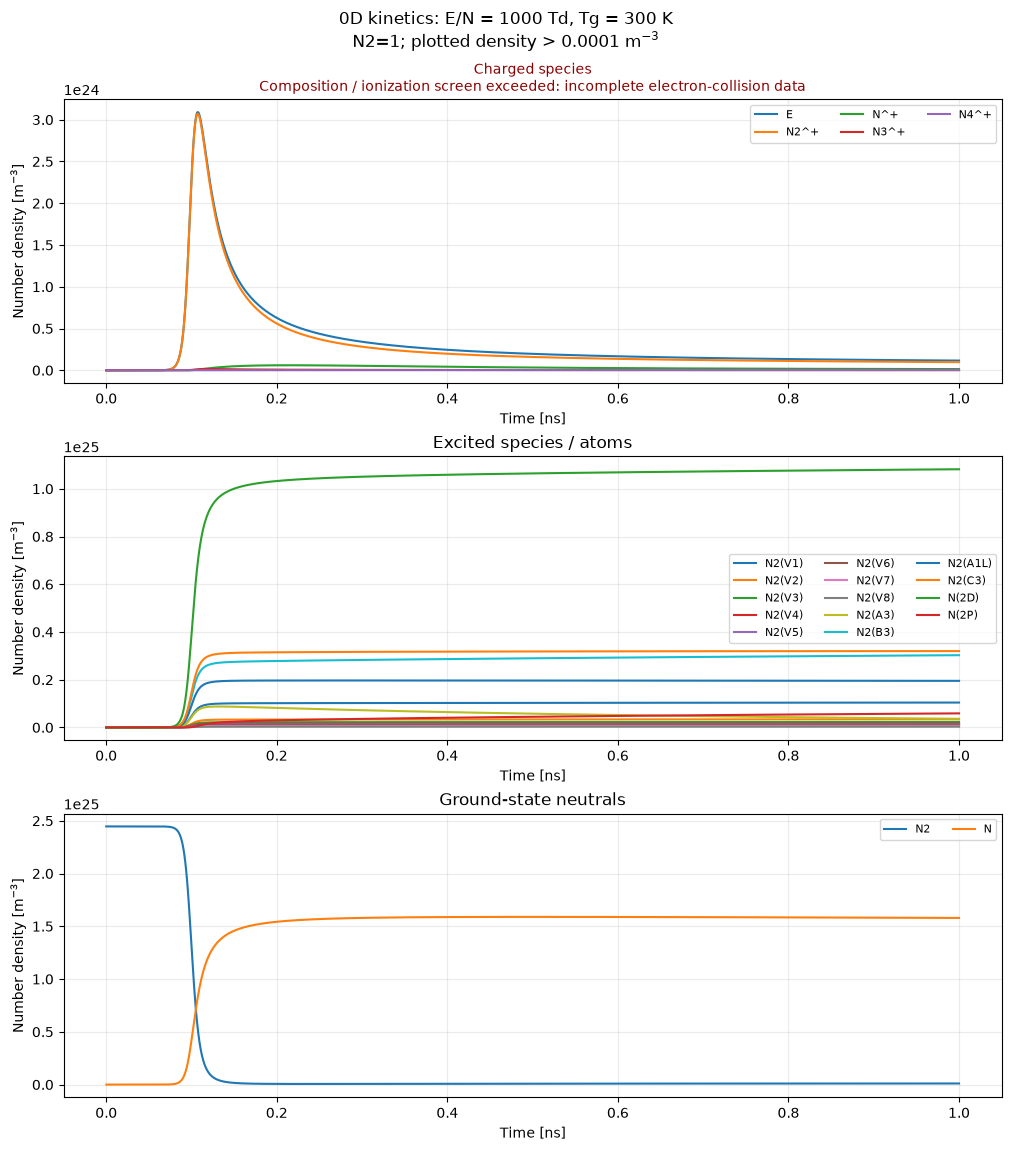

In [ ]:
fig = plot_result(result)

## 反応経路解析

`TARGET_SPECIES` の生成・消滅に寄与する反応を、指定した時間区間で積算して順位付けします。
対象種は `N`、`N2^+`、`N2(A3)`、`E` などに変更できます。
`TIME_RANGE_S` は秒単位です。初期値は計算した全区間です。

積算値は保存した密度からの台形積分です。短い反応ピークを調べる場合は、
ケースの `solver.points` を増やして収束を確認してください。
係数更新時刻では積分区間を分割し、最終時刻の係数を全区間へ流用しません。
順位表は正味の生成・消滅寄与を示します。グラフ用データは全反応について
「化学種 → 反応 → 化学種」を表し、原子の移動先を仮定しません。
電子など両辺に同数ある粒子はグラフに含まれますが、正味寄与の順位には入りません。
第三体グループの影響は反応速度に含み、物質移動の節点にはしません。

In [16]:
from plasglo import analyze_pathways, save_pathways

TARGET_SPECIES = "N"
TIME_RANGE_S = (float(result.time[0]), float(result.time[-1]))
pathways = analyze_pathways(result, TARGET_SPECIES, TIME_RANGE_S)

for title, rows in (
    ("生成への積算寄与", pathways.production),
    ("消滅への積算寄与", pathways.loss),
):
    print(f"\n{TARGET_SPECIES}: {title}（上位5反応）")
    for row in rows[:5]:
        print(
            f"{row['reaction_id']:>5}: {row['integrated_m3']:.4e} m^-3 "
            f"({row['fraction']:.2%})  {row['equation']}"
        )

net_integral = float(pathways.integrated_contributions_m3.sum())
print(f"\n正味の積算寄与: {net_integral:.6e} m^-3")
print(f"区間両端の密度差: {pathways.density_change_m3:.6e} m^-3")
print(
    "積算と密度差の差: "
    f"{net_integral - pathways.density_change_m3:.6e} m^-3"
)
print(
    f"グラフ: {len(pathways.graph['nodes'])} nodes, "
    f"{len(pathways.graph['edges'])} edges"
)



N: 生成への積算寄与（上位5反応）
 R022: 8.2566e+24 m^-3 (49.09%)  E + N2 -> E + N + N(2D)
 R024: 5.6839e+24 m^-3 (33.80%)  E + N2^+ -> N + N
 R025: 2.5578e+24 m^-3 (15.21%)  E + N2^+ -> N + N(2D)
 R026: 2.8420e+23 m^-3 (1.69%)  E + N2^+ -> N + N(2P)
 R027: 2.3854e+22 m^-3 (0.14%)  E + N3^+ -> N2 + N

N: 消滅への積算寄与（上位5反応）
 R044: 3.1996e+23 m^-3 (31.15%)  N2(A3) + N -> N2 + N(2P)
 R031: 1.8261e+23 m^-3 (17.78%)  N2^+ + N -> N^+ + N2
 R036: 1.6845e+23 m^-3 (16.40%)  N^+ + N + ANY_NEUTRAL -> N2^+ + ANY_NEUTRAL
 R064: 1.5844e+23 m^-3 (15.43%)  N + N + N -> N2 + N
 R062: 9.6357e+22 m^-3 (9.38%)  N + N + N -> N2(B3) + N

正味の積算寄与: 1.579090e+25 m^-3
区間両端の密度差: 1.579089e+25 m^-3
積算と密度差の差: 1.149081e+17 m^-3
グラフ: 117 nodes, 362 edges


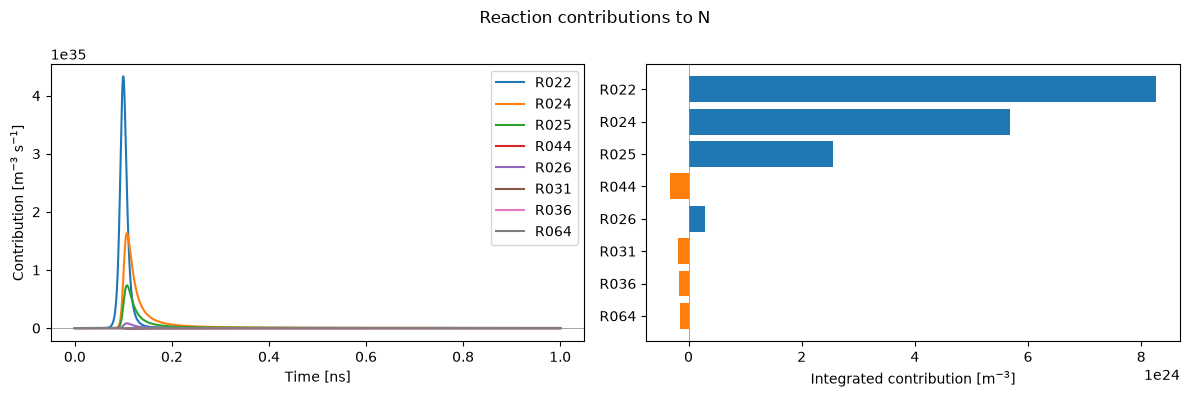

In [17]:
import matplotlib.pyplot as plt
import numpy as np

top_indices = np.argsort(
    -np.abs(pathways.integrated_contributions_m3), kind="stable"
)[:8]
top_indices = [
    j for j in top_indices if pathways.integrated_contributions_m3[j] != 0
]
pathway_figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for j in top_indices:
    axes[0].plot(
        pathways.time_s * 1e9, pathways.contributions_m3_s[j],
        label=pathways.reaction_ids[j],
    )
axes[0].set(xlabel="Time [ns]", ylabel="Contribution [m$^{-3}$ s$^{-1}$]")
axes[0].axhline(0, color="gray", linewidth=0.5)
if top_indices:
    axes[0].legend()
values = pathways.integrated_contributions_m3[top_indices]
axes[1].barh(
    [pathways.reaction_ids[j] for j in top_indices], values,
    color=["tab:blue" if value > 0 else "tab:orange" for value in values],
)
axes[1].invert_yaxis()
axes[1].set(xlabel="Integrated contribution [m$^{-3}$]")
axes[1].axvline(0, color="gray", linewidth=0.5)
pathway_figure.suptitle(f"Reaction contributions to {TARGET_SPECIES}")
pathway_figure.tight_layout()


## 保存

In [18]:
save_result(result, OUTPUT_DIR)
PATHWAY_DIR = OUTPUT_DIR / "pathways" / TARGET_SPECIES
save_pathways(pathways, PATHWAY_DIR)
pathway_figure.savefig(PATHWAY_DIR / "contributions.png", dpi=160)
print(f"保存先：{OUTPUT_DIR.resolve()}")
print(f"反応経路解析：{PATHWAY_DIR.resolve()}")


保存先：C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\outputs\notebooks\nitrogen
反応経路解析：C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\outputs\notebooks\nitrogen\pathways\N


## ZDPlasKinとの比較とモデルの範囲

`verification/validate_nitrogen.py` が同じ入力でZDPlasKinを再実行して比較します。
BOLOSにない電子間衝突を無効にした対照と、元の設定の結果を分けて評価します。
基底状態N₂以外の電子衝突、超弾性衝突、気体加熱、電子エネルギーODEは含みません。
高電離・強解離時の断面積範囲には制約があります。

[入力形式](../docs/GAS_CASES.md) / [元入力と出典](../samples/gases/README.md)